# Análisis exploratorio de datos (EDA) · Segmentación de manzanas

**Visión por Computador I · 2026/27** — María Mestre Sánchez, Elena Fernández Cebrián, Alejandro Operé Sirvent

## Objetivo

Antes de elegir filtros, espacios de color o modelos hay que **entender los datos**. Este notebook es la fase 0 del pipeline:
no transforma las imágenes que usarán los modelos, sino que las **mide** para que cada decisión del preprocesado y de los
modelos esté justificada con números y no se elija "a ver qué pasa".

Preguntas que responde:

| # | Pregunta | Para qué sirve |
|---|---|---|
| 1 | ¿El dataset está completo y es coherente? | Poder confiar en los datos |
| 2 | ¿Qué variedades de manzana hay y en qué imágenes? | Estratificar el split y analizar por variedad |
| 3 | ¿Cómo repartimos train / validación / test? | Evaluación honesta |
| 4 | ¿Cuánta área ocupan las manzanas? | Elegir métricas adecuadas al desbalanceo |
| 5 | ¿Qué canal de color separa mejor manzana y fondo? ¿Sirve el gris estándar? | Espacio de color del preprocesado (tema 2) |
| 6 | ¿Qué "gris de manzana" (color → un canal) funciona mejor? | Configuraciones P5/P6 del preprocesado |
| 7 | ¿Qué tamaño y forma tienen las manzanas? | Morfología, filtro de área, Hough, watershed (temas 3, 4 y 5) |
| 8 | ¿Cómo es la iluminación? ¿Hay ruido? | Elegir CLAHE, gamma y filtros de ruido (temas 3 y 6) |
| 9 | ¿Las anotaciones son completas? | Interpretar bien los falsos positivos |

**Regla:** el conjunto de **test no se usa en ningún momento**. Todo se calcula con train, salvo la comparación de candidatos a
"gris de manzana", que se ajusta en train y se **mide en validación** (igual que se hará con Optuna).

Solo se usan OpenCV, NumPy y Matplotlib (sin scikit-learn ni SciPy). Las funciones reutilizables en las fases siguientes
están en `src/` (carga de datos, canales de color, curvas ROC/PR, medidas por objeto y ruido).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():  # el notebook vive en experimentos/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import csv

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from config import EDA_OUTPUT_DIR, IMAGE_SCALE, RANDOM_SEED, YELLOW_IMAGE_MAX_INDEX
from src.datos.loader import load_dataset, stratified_split
from src.metricas.curvas import curves_from_histograms, score_histograms
from src.metricas.objeto import component_stats, disc_reference
from src.metricas.pixel import pixel_metrics
from src.preprocesado.color import (
    CHANNEL_ORDER, FIXED_CANDIDATES, LEARNED_CANDIDATES, HistogramBackprojection, channel_images,
)
from src.preprocesado.ruido import estimate_gaussian_noise, impulse_noise_fraction

OUT = Path(EDA_OUTPUT_DIR)
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})
get_ipython().run_line_magic("config", 'InlineBackend.figure_formats = ["jpeg"]')  # notebook ligero
COLORS = {"amarilla": "#d4a017", "roja": "#c0392b", "todas": "#4a4a4a"}
GROUPS = ("todas", "amarilla", "roja")
rng = np.random.default_rng(RANDOM_SEED)


def fmt(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


def table(rows, columns, headers=None):
    # Muestra una lista de diccionarios como tabla Markdown.
    headers = headers or columns
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    for r in rows:
        lines.append("| " + " | ".join(str(r[c]) for c in columns) + " |")
    display(Markdown("\n".join(lines)))


def save_csv(rows, name):
    with (OUT / name).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def save_fig(fig, name):
    fig.savefig(OUT / name, dpi=130, bbox_inches="tight")
    plt.show()


def resize(sample, scale=IMAGE_SCALE):
    # Imagen con INTER_AREA (promedia, no inventa colores) y máscara con INTER_NEAREST (sigue binaria).
    size = (round(sample.image.shape[1] * scale), round(sample.image.shape[0] * scale))
    image = cv2.resize(sample.image, size, interpolation=cv2.INTER_AREA)
    mask = cv2.resize(sample.mask.astype(np.uint8), size, interpolation=cv2.INTER_NEAREST) > 0
    return image, mask


print("Resultados en:", OUT)

Resultados en: C:\Users\aleja\Desktop\4ANYO\1CUATRI\visionComp\proyecto\SegmentacionManzanas\resultados\eda


## 1. Carga y verificación del dataset

`load_dataset()` empareja cada imagen con su máscara por nombre, convierte BGR → RGB (OpenCV lee en BGR), binariza la
máscara (`> 127`) y comprueba que todas las imágenes tienen la misma resolución. Si falta una máscara o un tamaño no
cuadra, lanza un error en lugar de seguir con datos corruptos.

In [2]:
samples = load_dataset()
by_id = {s.image_id: s for s in samples}
shapes = {s.image.shape for s in samples}
print(f"Imágenes: {len(samples)}  ·  resolución: {shapes}  ·  tipo: {samples[0].image.dtype}")
print(f"Máscaras binarias: {all(s.mask.dtype == bool for s in samples)}  ·  "
      f"todas con alguna manzana: {all(s.mask.any() for s in samples)}")
print(f"Resolución de trabajo (escala {IMAGE_SCALE}): {resize(samples[0])[0].shape}")

Imágenes: 100  ·  resolución: {(1280, 720, 3)}  ·  tipo: uint8


Máscaras binarias: True  ·  todas con alguna manzana: True
Resolución de trabajo (escala 0.5): (640, 360, 3)


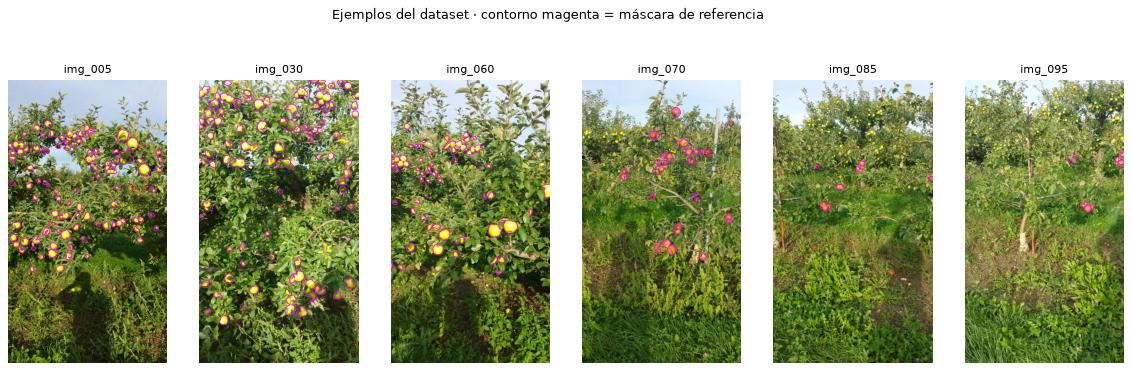

In [3]:
example_ids = ["img_005", "img_030", "img_060", "img_070", "img_085", "img_095"]
fig, axes = plt.subplots(1, len(example_ids), figsize=(18, 5.5))
for ax, image_id in zip(axes, example_ids):
    s = by_id[image_id]
    image, mask = resize(s)
    ax.imshow(image)
    ax.contour(mask, levels=[0.5], colors="#ff00ff", linewidths=0.6)
    ax.set_title(f"{image_id}", fontsize=10)
    ax.axis("off")
fig.suptitle("Ejemplos del dataset · contorno magenta = máscara de referencia")
save_fig(fig, "ejemplos_dataset.png")

**Observaciones.** 100 imágenes verticales de 720×1280 con su máscara; todas tienen al menos una manzana anotada.
Se ven dos escenas distintas: árboles grandes cargados de **manzanas amarillo-verdosas** y árboles jóvenes con pocas
**manzanas rojas**. En ambas, el fondo (hojas, césped) es verde y las manzanas son pequeñas respecto a la imagen.
Trabajaremos a escala 0,5 (360×640) para que el ajuste de hiperparámetros sea rápido; las estadísticas de forma se miden a
resolución original para no perder las manzanas pequeñas.

## 2. Variedades: ¿qué imágenes son amarillas y cuáles rojas?

Hay que saberlo por dos motivos: **estratificar** el split (que train, validación y test tengan las dos variedades en la
misma proporción) y **analizar por separado**, porque un canal que funciona con una variedad puede fallar con la otra.

En vez de fiarnos de una estimación visual, lo medimos: para cada imagen, la fracción de píxeles de manzana claramente
rojos, usando el canal a\* de Lab (eje verde → rojo, tema 2; en OpenCV a\* va de 0 a 255 con el neutro en 128).

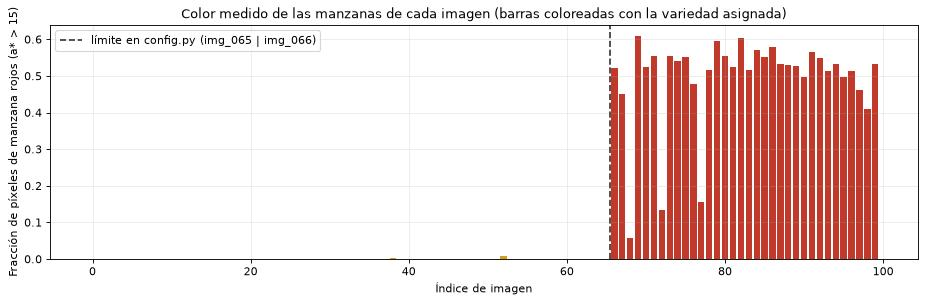

Amarillas: 66 (img_000–img_065)  ·  Rojas: 34 (img_066–img_099)
Amarillas con alguna fracción roja > 0,05: []
Rojas con fracción roja < 0,3: ['img_068', 'img_072', 'img_077']


In [4]:
red_fraction = []
for s in samples:
    a_star = cv2.cvtColor(s.image, cv2.COLOR_RGB2LAB)[:, :, 1][s.mask].astype(int) - 128
    red_fraction.append(float(np.mean(a_star > 15)))
red_fraction = np.array(red_fraction)
index = np.arange(len(samples))

fig, ax = plt.subplots(figsize=(14, 3.8))
ax.bar(index, red_fraction, color=[COLORS[s.variety] for s in samples])
ax.axvline(YELLOW_IMAGE_MAX_INDEX + 0.5, color="#333", linestyle="--",
           label=f"límite en config.py (img_{YELLOW_IMAGE_MAX_INDEX:03d} | img_{YELLOW_IMAGE_MAX_INDEX + 1:03d})")
ax.set(xlabel="Índice de imagen", ylabel="Fracción de píxeles de manzana rojos (a* > 15)",
       title="Color medido de las manzanas de cada imagen (barras coloreadas con la variedad asignada)")
ax.legend()
save_fig(fig, "variedades.png")

yellow = [s for s in samples if s.variety == "amarilla"]
red = [s for s in samples if s.variety == "roja"]
print(f"Amarillas: {len(yellow)} ({yellow[0].image_id}–{yellow[-1].image_id})  ·  "
      f"Rojas: {len(red)} ({red[0].image_id}–{red[-1].image_id})")
print("Amarillas con alguna fracción roja > 0,05:", [s.image_id for s, f in zip(samples, red_fraction)
                                                     if s.variety == "amarilla" and f > 0.05])
print("Rojas con fracción roja < 0,3:", [s.image_id for s, f in zip(samples, red_fraction)
                                         if s.variety == "roja" and f < 0.3])

**Resultado.** Las imágenes `img_000`–`img_065` son del huerto amarillo (fracción roja ≈ 0) y `img_066`–`img_099` de la
escena de manzanas rojas: **66 amarillas y 34 rojas**. La primera versión del proyecto suponía el límite en `img_049`
(una estimación a ojo), lo que clasificaba 16 imágenes amarillas como rojas; por eso el límite se ha verificado así y está
fijado en `config.py`.

Algunas imágenes de la escena roja (`img_068`, `img_072`, `img_077`) tienen poca fracción roja: son árboles jóvenes con
manzanas bicolores o todavía verdosas. Siguen siendo la misma escena y variedad, y así se etiquetan.

## 3. Partición train / validación / test (60/20/20)

- **Por imagen**, nunca por píxel: los píxeles de una misma imagen están muy correlacionados; mezclarlos entre train y
  test inflaría las métricas.
- **Estratificada por variedad** y con **semilla fija** (reproducible).
- Los sobrantes del redondeo se reparten por el método del **mayor resto**, para que el total sea exactamente 60/20/20.
- **Train** se usa para aprender (histogramas, modelos supervisados); **validación** para comparar y ajustar
  hiperparámetros (Optuna); **test** solo una vez, al final de cada experimento.

In [5]:
split = stratified_split(samples)
train = [by_id[i] for i in split.train]
validation = [by_id[i] for i in split.validation]
split_rows = []
for name, subset in (("train", train), ("validación", validation), ("test", [by_id[i] for i in split.test])):
    prevalences = [float(s.mask.mean()) for s in subset]
    split_rows.append({
        "split": name, "imagenes": len(subset),
        "amarillas": sum(s.variety == "amarilla" for s in subset),
        "rojas": sum(s.variety == "roja" for s in subset),
        "prevalencia": sum(int(s.mask.sum()) for s in subset) / sum(s.mask.size for s in subset),
        "prev_min": min(prevalences), "prev_max": max(prevalences),
    })
save_csv(split_rows, "split_resumen.csv")
table([{**r, "prevalencia": pct(r["prevalencia"], 2), "rango": f"{pct(r['prev_min'], 2)} – {pct(r['prev_max'], 2)}"}
       for r in split_rows],
      ["split", "imagenes", "amarillas", "rojas", "prevalencia", "rango"],
      ["Split", "Imágenes", "Amarillas", "Rojas", "Píxeles de manzana", "Rango por imagen"])

| Split | Imágenes | Amarillas | Rojas | Píxeles de manzana | Rango por imagen |
|---|---|---|---|---|---|
| train | 60 | 40 | 20 | 4,39 % | 0,24 % – 10,06 % |
| validación | 20 | 13 | 7 | 4,37 % | 0,22 % – 9,21 % |
| test | 20 | 13 | 7 | 3,75 % | 0,25 % – 8,99 % |

## 4. Desbalanceo: ¿cuánta área ocupan las manzanas?

La tabla anterior ya lo adelanta: solo un ~4 % de los píxeles son manzana. Veamos la distribución por imagen y qué
consecuencia tiene sobre las métricas (tema 5) con un "modelo" trivial que predice **todo fondo**.

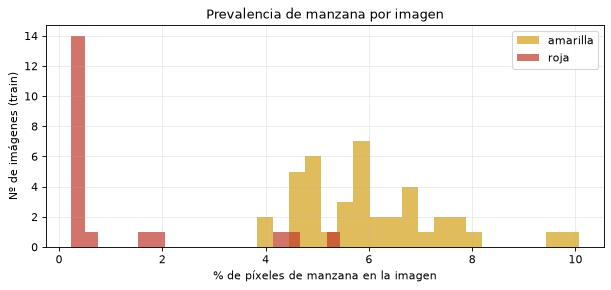

Predecir TODO fondo en train →  accuracy: 0,956  ·  precision: 0,000  ·  recall: 0,000  ·  f1: 0,000  ·  iou: 0,000  ·  mcc: 0,000


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for variety in ("amarilla", "roja"):
    ax.hist([100 * s.mask.mean() for s in train if s.variety == variety], bins=20, alpha=0.7,
            color=COLORS[variety], label=variety)
ax.set(xlabel="% de píxeles de manzana en la imagen", ylabel="Nº de imágenes (train)",
       title="Prevalencia de manzana por imagen")
ax.legend()
save_fig(fig, "prevalencia.png")

gt = np.concatenate([s.mask.ravel() for s in train])
trivial = pixel_metrics(gt, np.zeros_like(gt))
print("Predecir TODO fondo en train →  " + "  ·  ".join(
    f"{k}: {fmt(trivial[k])}" for k in ("accuracy", "precision", "recall", "f1", "iou", "mcc")))

**Conclusión.** Un modelo que no detecta ninguna manzana obtiene una *accuracy* de ~0,96 y, sin embargo, F1, IoU y MCC
valen 0. Por tanto:

- La **accuracy no sirve** como métrica principal; se usarán **F1/Dice, IoU, MCC** y, para los mapas de puntuación,
  el **área bajo la curva precisión-recall (PR-AUC / AP)**, más informativa que el ROC-AUC con este desbalanceo.
- Los modelos supervisados se entrenarán con un **muestreo balanceado** de píxeles; si no, aprenderían a decir "fondo".
- Las rojas tienen muy poca manzana por imagen (árboles jóvenes): serán las más difíciles.

## 5. ¿Qué canal de color separa la manzana del fondo?

El profesor sugiere no quedarse con el gris estándar. Para comprobarlo medimos cada canal de los espacios de color del
**tema 2** (RGB, HSV, Lab, YCrCb y gris) como si fuera un clasificador por sí solo. Se añade un canal más: la
**distancia circular del matiz al rojo**. En OpenCV, H va de 0 a 179 y el rojo está en *los dos extremos* (≈0 y ≈179), así
que un umbral sobre H en bruto parte las manzanas rojas en dos; `min(H, 180 − H)` pone el rojo en 0.

Dos medidas de separabilidad:

- **ROC-AUC** (tema 5): probabilidad de que un píxel de manzana elegido al azar tenga un valor mayor que uno de fondo
  (0,5 = azar, 1 = separación perfecta). Se toma el mejor sentido (mayor o menor), porque en algunos canales la manzana
  es más *baja* (p. ej. Cb).
- **Varianza interclase / intraclase**: el mismo criterio que maximiza Otsu (tema 5). Si es alto, un umbral global
  separará bien.

Para que las imágenes con muchas manzanas no dominen, se muestrean hasta 5000 píxeles de cada clase por imagen (train,
escala 0,5). Se calcula para todas las imágenes juntas y **por variedad**.

In [7]:
MAX_PER_CLASS = 5000


def sample_pixels(subset):
    # Valores de cada canal para píxeles de manzana y de fondo (muestreo balanceado por imagen).
    local_rng = np.random.default_rng(RANDOM_SEED)
    pos = {k: [] for k in CHANNEL_ORDER}
    neg = {k: [] for k in CHANNEL_ORDER}
    for s in subset:
        image, mask = resize(s)
        idx_pos, idx_neg = np.flatnonzero(mask), np.flatnonzero(~mask)
        idx_pos = local_rng.choice(idx_pos, min(MAX_PER_CLASS, idx_pos.size), replace=False)
        idx_neg = local_rng.choice(idx_neg, min(MAX_PER_CLASS, idx_neg.size), replace=False)
        for key, channel in channel_images(image).items():
            pos[key].append(channel.ravel()[idx_pos])
            neg[key].append(channel.ravel()[idx_neg])
    return ({k: np.concatenate(v) for k, v in pos.items()},
            {k: np.concatenate(v) for k, v in neg.items()})


separability, channel_hist = [], {}
for group in GROUPS:
    subset = [s for s in train if group == "todas" or s.variety == group]
    pos, neg = sample_pixels(subset)
    for key in CHANNEL_ORDER:
        hp, hn = np.bincount(pos[key], minlength=256), np.bincount(neg[key], minlength=256)
        auc = curves_from_histograms(hp, hn)["roc_auc"]
        wp = pos[key].size / (pos[key].size + neg[key].size)
        mp, mn = pos[key].mean(), neg[key].mean()
        between = wp * (1 - wp) * (mp - mn) ** 2
        within = wp * pos[key].var() + (1 - wp) * neg[key].var()
        channel_hist[(group, key)] = (hp, hn)
        separability.append({
            "variedad": group, "espacio": key[0], "canal": key[1], "imagenes": len(subset),
            "media_manzana": mp, "media_fondo": mn, "auc": max(auc, 1 - auc),
            "sentido": "mayor" if auc >= 0.5 else "menor", "inter_intra": between / within,
        })
save_csv(separability, "separabilidad_canales.csv")

auc_of = {(r["variedad"], r["espacio"], r["canal"]): r for r in separability}
KEY_CHANNELS = [("Gris", "Y", "Gris estándar Y"), ("Lab", "a*", "a* (Lab)"), ("Lab", "b*", "b* (Lab)"),
                ("YCrCb", "Cr", "Cr (YCrCb)"), ("YCrCb", "Cb", "Cb (YCrCb)"), ("HSV", "H", "H en bruto"),
                ("Matiz", "dist_rojo", "Dist. circular al rojo"), ("HSV", "S", "S (HSV)"), ("RGB", "R", "R (RGB)")]
table([{"canal": label,
        **{g: fmt(auc_of[(g, sp, ch)]["auc"]) + ("" if auc_of[(g, sp, ch)]["sentido"] == "mayor" else " ↓")
           for g in GROUPS},
        "ratio": fmt(auc_of[("todas", sp, ch)]["inter_intra"])}
       for sp, ch, label in KEY_CHANNELS],
      ["canal", "todas", "amarilla", "roja", "ratio"],
      ["Canal", "AUC todas", "AUC amarillas", "AUC rojas", "Inter/intra (todas)"])
print("↓ = la manzana tiene valores MENORES que el fondo en ese canal")

| Canal | AUC todas | AUC amarillas | AUC rojas | Inter/intra (todas) |
|---|---|---|---|---|
| Gris estándar Y | 0,734 | 0,757 | 0,646 | 0,194 |
| a* (Lab) | 0,533 ↓ | 0,639 ↓ | 0,929 | 0,003 |
| b* (Lab) | 0,873 | 0,895 | 0,765 | 0,662 |
| Cr (YCrCb) | 0,881 | 0,876 | 0,968 | 0,545 |
| Cb (YCrCb) | 0,880 ↓ | 0,900 ↓ | 0,781 ↓ | 0,715 |
| H en bruto | 0,823 ↓ | 0,820 ↓ | 0,945 ↓ | 0,173 |
| Dist. circular al rojo | 0,825 ↓ | 0,820 ↓ | 0,950 ↓ | 0,259 |
| S (HSV) | 0,681 | 0,683 | 0,649 | 0,108 |
| R (RGB) | 0,788 | 0,792 | 0,799 | 0,331 |

↓ = la manzana tiene valores MENORES que el fondo en ese canal


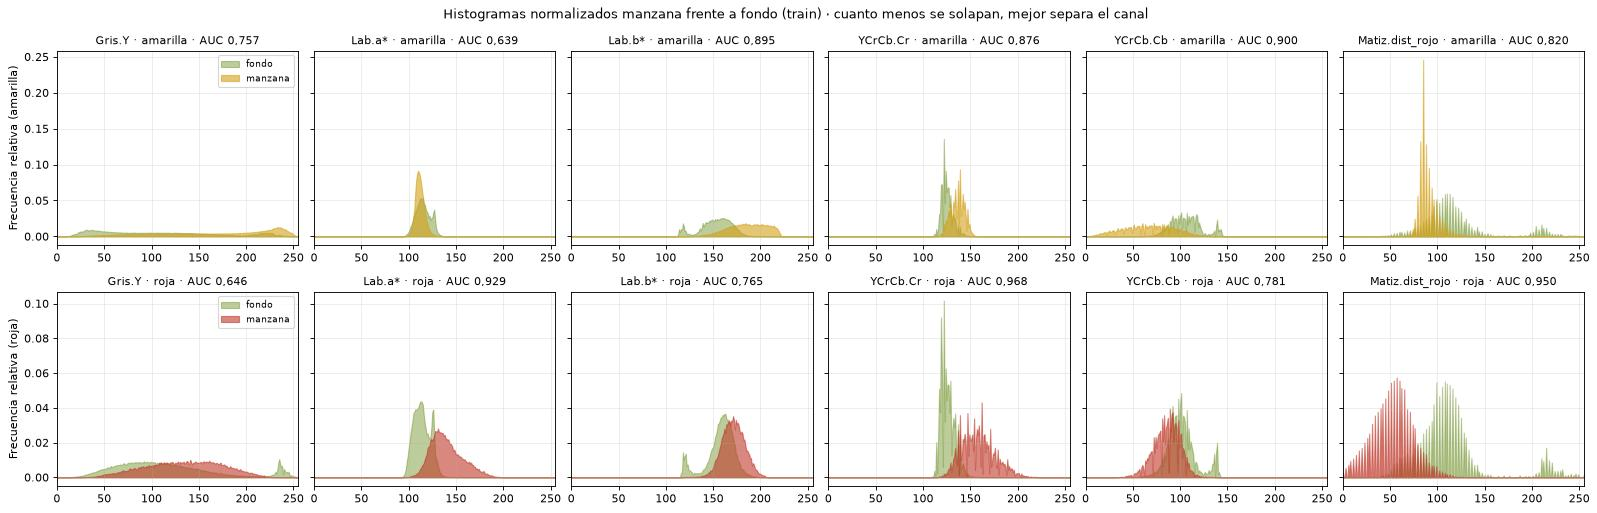

In [8]:
SHOW = [("Gris", "Y"), ("Lab", "a*"), ("Lab", "b*"), ("YCrCb", "Cr"), ("YCrCb", "Cb"), ("Matiz", "dist_rojo")]
fig, axes = plt.subplots(2, len(SHOW), figsize=(20, 6.5), sharey="row")
for row, variety in enumerate(("amarilla", "roja")):
    for ax, key in zip(axes[row], SHOW):
        hp, hn = channel_hist[(variety, key)]
        ax.fill_between(range(256), hn / hn.sum(), color="#6b8e23", alpha=0.45, label="fondo")
        ax.fill_between(range(256), hp / hp.sum(), color=COLORS[variety], alpha=0.6, label="manzana")
        ax.set_title(f"{key[0]}.{key[1]} · {variety} · AUC {fmt(auc_of[(variety, *key)]['auc'])}", fontsize=10)
        ax.set_xlim(0, 255)
    axes[row, 0].set_ylabel(f"Frecuencia relativa ({variety})")
    axes[row, 0].legend(fontsize=8)
fig.suptitle("Histogramas normalizados manzana frente a fondo (train) · cuanto menos se solapan, mejor separa el canal")
fig.tight_layout()
save_fig(fig, "histogramas_canales.png")

**Interpretación.**

- El **gris estándar separa mal**, sobre todo en las rojas (AUC ≈ 0,65): una manzana roja y una hoja pueden tener el
  mismo brillo. Se confirma la intuición del profesor: hay que convertir el color de otra forma.
- **Cada variedad tiene su canal**: las amarillas se separan mejor por el eje azul–amarillo (**Cb** ↓, **b\***, ≈ 0,90) y
  las rojas por el eje rojo (**Cr** ≈ 0,97, **a\*** ≈ 0,93, matiz ≈ 0,95).
- **Mezclar variedades engaña**: a\* parece inútil con todas juntas (≈ 0,53) y es casi perfecto en las rojas. Sin el
  análisis por variedad lo habríamos descartado.
- El matiz en bruto y la distancia circular dan AUC parecido porque el AUC elige el mejor sentido, pero solo la distancia
  circular permite **un único umbral** para todo el rojo; es la versión que usará el preprocesado.
- **Ningún canal funciona bien para las dos variedades a la vez**: motiva combinar canales (siguiente sección).

## 6. "Gris de manzana": convertir el color en un solo canal donde la manzana destaque

Un **gris de manzana** es una imagen de un solo canal (0–255) calculada a partir del color, en la que la manzana sale
**clara** y el fondo **oscuro**. Es lo que entendemos por la nota del profesor ("al pasar a gris, el rojo pasa a amarillo
y queda más visible"): no usar el brillo, sino una transformación del color. Todos los candidatos salen del temario:

| Candidato | Definición | Tema |
|---|---|---|
| Gris estándar Y | 0,299R + 0,587G + 0,114B (referencia) | 2 |
| Cr, b\*, 255 − Cb | un canal de YCrCb o Lab | 2 |
| max(a\*, b\*) | cada variedad destaca en uno de los dos ejes de Lab | 2, 3 |
| (Cr + 255 − Cb) / 2 | rojo **y** amarillo lejos del azul/verde a la vez | 2, 3 |
| Matiz cercano al rojo | 255 − distancia circular del matiz al rojo | 2 |
| **Retroproyección del histograma** | histograma 2D de colores de manzana y de fondo en train, normalizados (tema 6: "interpretar probabilidades"); cada píxel recibe P(manzana \| color) con `cv2.calcBackProject` | 6 |

Las retroproyecciones **aprenden** en train; todos los candidatos se **miden en validación** con **todos** los píxeles
(sin muestrear), y se reportan:

- **ROC-AUC**: no depende del desbalanceo.
- **AP (Average Precision, área PR)**: parte de la prevalencia (~4 %) y penaliza confundir mucho fondo con manzana; es
  la que más se parece a lo que pasará al umbralizar.

In [9]:
train_small = [resize(s) for s in train]
learned = {name: HistogramBackprojection(**params).fit([i for i, _ in train_small], [m for _, m in train_small])
           for name, params in LEARNED_CANDIDATES.items()}
candidates = {**FIXED_CANDIDATES, **learned}

hist = {(n, g): [np.zeros(256, np.int64), np.zeros(256, np.int64)] for n in candidates for g in GROUPS}
for s in validation:
    image, mask = resize(s)
    for name, function in candidates.items():
        hp, hn = score_histograms(function(image), mask)
        for g in ("todas", s.variety):
            hist[(name, g)][0] += hp
            hist[(name, g)][1] += hn

candidate_rows, curves = [], {}
for name in candidates:
    for g in GROUPS:
        r = curves_from_histograms(*hist[(name, g)])
        if g == "todas":
            curves[name] = r
        candidate_rows.append({"candidato": name, "aprendido": name in learned, "variedad": g,
                               "prevalencia": r["prevalence"], "roc_auc": r["roc_auc"],
                               "ap": r["average_precision"], "mejor_f1_orientativo": r["best_f1"],
                               "umbral_mejor_f1": r["best_f1_threshold"]})
save_csv(candidate_rows, "candidatos_gris_manzana.csv")

get = lambda n, g, k: next(r[k] for r in candidate_rows if r["candidato"] == n and r["variedad"] == g)
order = sorted(candidates, key=lambda n: get(n, "todas", "ap"), reverse=True)
table([{"c": n, "l": "sí" if n in learned else "no", "auc": fmt(get(n, "todas", "roc_auc")),
        "ap": f"**{fmt(get(n, 'todas', 'ap'))}**", "apy": fmt(get(n, "amarilla", "ap")),
        "apr": fmt(get(n, "roja", "ap"))} for n in order],
      ["c", "l", "auc", "ap", "apy", "apr"],
      ["Candidato", "Aprendido", "AUC todas", "AP todas", "AP amarillas", "AP rojas"])
print(f"Prevalencia en validación (AP de un clasificador al azar): {fmt(get(order[0], 'todas', 'prevalencia'))}")

| Candidato | Aprendido | AUC todas | AP todas | AP amarillas | AP rojas |
|---|---|---|---|---|---|
| (Cr + 255 − Cb) / 2 | no | 0,895 | **0,610** | 0,648 | 0,536 |
| Retroproyección Cr–Cb (YCrCb) | sí | 0,903 | **0,603** | 0,641 | 0,471 |
| Retroproyección a*–b* (Lab) | sí | 0,899 | **0,584** | 0,624 | 0,458 |
| 255 − Cb (YCrCb) | no | 0,875 | **0,558** | 0,629 | 0,028 |
| max(a*, b*) | no | 0,869 | **0,545** | 0,613 | 0,033 |
| b* (Lab) | no | 0,867 | **0,543** | 0,613 | 0,027 |
| Cr (YCrCb) | no | 0,856 | **0,291** | 0,345 | 0,706 |
| Retroproyección H–S (HSV) | sí | 0,869 | **0,274** | 0,327 | 0,239 |
| Matiz cercano al rojo | no | 0,809 | **0,128** | 0,165 | 0,435 |
| Gris estándar Y | no | 0,741 | **0,126** | 0,194 | 0,010 |

Prevalencia en validación (AP de un clasificador al azar): 0,044


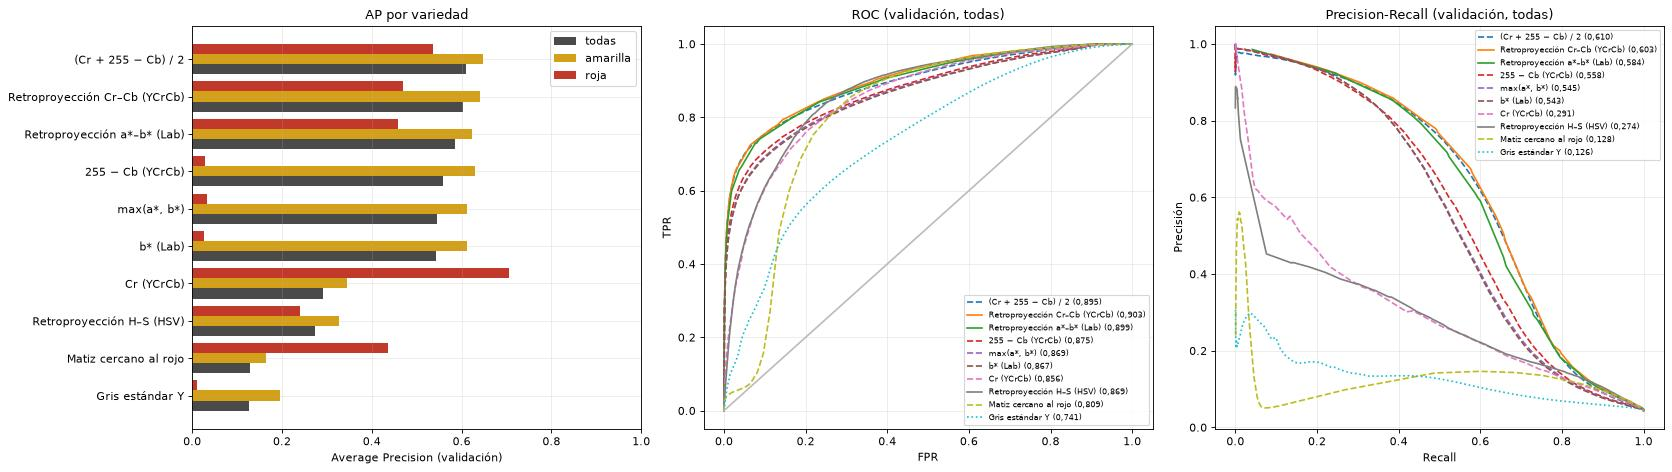

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
y = np.arange(len(order))[::-1]
for offset, g in zip((-0.27, 0, 0.27), GROUPS):
    axes[0].barh(y + offset, [get(n, g, "ap") for n in order], height=0.27, color=COLORS[g], label=g)
axes[0].set_yticks(y, order)
axes[0].set(xlabel="Average Precision (validación)", xlim=(0, 1), title="AP por variedad")
axes[0].legend()
for name in order:
    r = curves[name]
    style = ":" if name == "Gris estándar Y" else ("-" if name in learned else "--")
    axes[1].plot(r["fpr"], r["tpr"], style, label=f"{name} ({fmt(r['roc_auc'])})")
    axes[2].plot(r["recall"], r["precision"], style, label=f"{name} ({fmt(r['average_precision'])})")
axes[1].plot([0, 1], [0, 1], color="#bbb")
axes[1].set(xlabel="FPR", ylabel="TPR", title="ROC (validación, todas)")
axes[2].set(xlabel="Recall", ylabel="Precisión", title="Precision-Recall (validación, todas)")
for ax in axes[1:]:
    ax.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "candidatos_gris_manzana.png")

**Interpretación.**

- El mejor candidato es **(Cr + 255 − Cb) / 2**, una transformación **fija** de canales de YCrCb: AP ≈ 0,61 frente a
  ≈ 0,13 del gris estándar (**casi 5 veces más**). Es la mejor traducción de la idea del profesor: rojo y amarillo quedan
  claros a la vez porque los dos están lejos del azul–verde del follaje.
- La **retroproyección Cr–Cb** queda prácticamente empatada (≈ 0,60) y la a\*–b\* cerca. En las rojas rinden menos porque
  train tiene muchas más manzanas amarillas y el histograma aprende sobre todo ese color. Se puede mejorar dando el
  mismo peso a cada variedad al construir el histograma.
- En las rojas gana **Cr** solo (AP ≈ 0,71), y los canales del eje amarillo (b\*, 255 − Cb, max(a\*, b\*)) se hunden a
  AP ≈ 0,03 aunque su AUC sea razonable: en esas imágenes resaltan, sobre todo, **manzanas amarillas de las filas del
  fondo, que no están anotadas** (sección 9).
- AUC y AP ordenan distinto a los candidatos: con este desbalanceo, el AP es el criterio para elegir.

**Decisión para el preprocesado:** (Cr + 255 − Cb)/2 como "gris de manzana" principal (P6), con la retroproyección como
alternativa aprendida; Cr como canal específico del rojo. El mejor F1 por umbral del CSV se elige sobre la propia
validación, así que es optimista y solo sirve para comparar.

Veamos qué aspecto tienen en dos imágenes de **validación** (una de cada variedad):

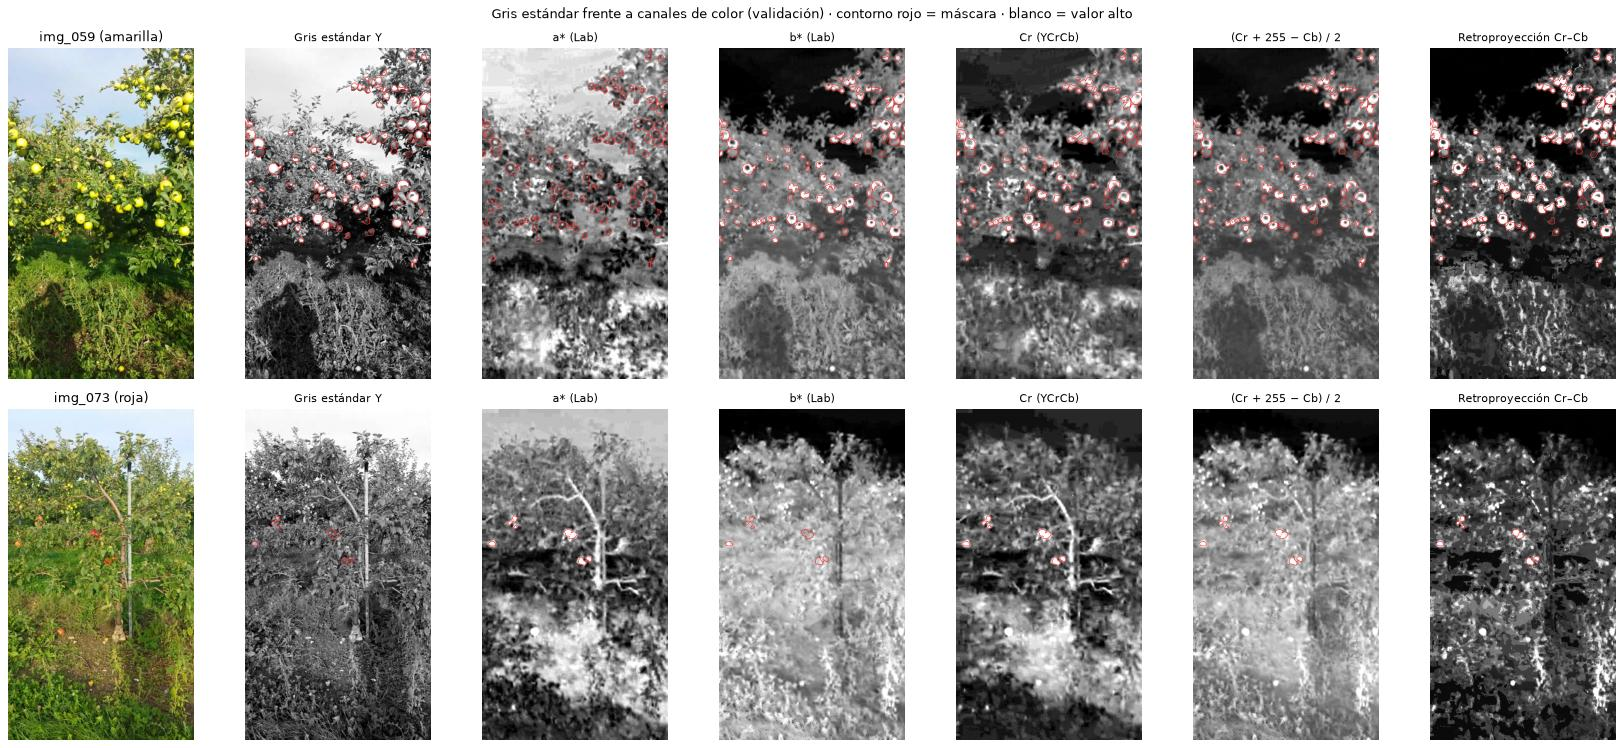

In [11]:
def stretch(x):
    lo, hi = np.percentile(x, (1, 99))
    return np.clip((x.astype(float) - lo) / max(hi - lo, 1e-9), 0, 1)


def pick(variety):
    subset = sorted((s for s in validation if s.variety == variety), key=lambda s: s.mask.mean())
    return subset[len(subset) // 2]  # prevalencia mediana: ni la más fácil ni la más difícil


panels = [("Gris estándar Y", FIXED_CANDIDATES["Gris estándar Y"]),
          ("a* (Lab)", lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2LAB)[:, :, 1]),
          ("b* (Lab)", FIXED_CANDIDATES["b* (Lab)"]),
          ("Cr (YCrCb)", FIXED_CANDIDATES["Cr (YCrCb)"]),
          ("(Cr + 255 − Cb) / 2", FIXED_CANDIDATES["(Cr + 255 − Cb) / 2"]),
          ("Retroproyección Cr–Cb", learned["Retroproyección Cr–Cb (YCrCb)"])]
fig, axes = plt.subplots(2, len(panels) + 1, figsize=(21, 9.5))
for row, variety in enumerate(("amarilla", "roja")):
    s = pick(variety)
    image, mask = resize(s)
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{s.image_id} ({variety})")
    for ax, (title, function) in zip(axes[row, 1:], panels):
        ax.imshow(stretch(function(image)), cmap="gray")
        ax.contour(mask, levels=[0.5], colors="#ff2d2d", linewidths=0.5)
        ax.set_title(title, fontsize=10)
    for ax in axes[row]:
        ax.axis("off")
fig.suptitle("Gris estándar frente a canales de color (validación) · contorno rojo = máscara · blanco = valor alto")
fig.tight_layout()
save_fig(fig, "canales_ejemplo.png")

En el gris estándar las manzanas rojas desaparecen entre el follaje; en Cr y en (Cr + 255 − Cb)/2 destacan en las dos
variedades. También se aprecia que el césped iluminado y algunos troncos quedan claros: un umbral solo no bastará y habrá
que filtrar por **forma y tamaño** (sección 7) o usar modelos con más información (textura, vecindad).

## 7. Tamaño y forma de las manzanas (componentes conexas, tema 5)

Cada **componente conexa** (8-vecindad) de la máscara es una manzana anotada, o varias que se tocan. A resolución
original medimos:

- **Radio equivalente** r = √(área / π) → filtro de área mínima, tamaño del elemento estructurante y rango de radios para
  la transformada de Hough de círculos (tema 4).
- **Circularidad** 4πA/P² (1 = círculo) → filtro de forma.
- **Solidez** A / A<sub>envolvente convexa</sub> → baja si hay varias manzanas fusionadas → justifica watershed.

Antes, una comprobación: en contornos **pixelados** el perímetro se sobreestima (escalones), así que un círculo perfecto
no da 1. Por eso normalizamos cada medida respecto a la de un **disco digital** del mismo radio.

In [12]:
for radius in (4, 7, 12, 24, 50):
    c, so = disc_reference(radius)
    print(f"Disco digital perfecto de radio {radius:>2} px → circularidad {fmt(c)}  ·  solidez {fmt(so)}")

Disco digital perfecto de radio  4 px → circularidad 0,766  ·  solidez 0,905
Disco digital perfecto de radio  7 px → circularidad 0,833  ·  solidez 0,942
Disco digital perfecto de radio 12 px → circularidad 0,859  ·  solidez 0,962
Disco digital perfecto de radio 24 px → circularidad 0,882  ·  solidez 0,980
Disco digital perfecto de radio 50 px → circularidad 0,891  ·  solidez 0,989


In [13]:
objects, per_image = [], []
for s in train:
    stats = component_stats(s.mask)
    per_image.append({"image_id": s.image_id, "variedad": s.variety, "manzanas": len(stats)})
    objects += [{"image_id": s.image_id, "variedad": s.variety, **st} for st in stats]
save_csv(objects, "objetos_componentes.csv")
save_csv(per_image, "objetos_por_imagen.csv")

LOW_SOLIDITY = 0.85
object_summary = {}
for g in GROUPS:
    o = [r for r in objects if g == "todas" or r["variedad"] == g]
    counts = [r["manzanas"] for r in per_image if g == "todas" or r["variedad"] == g]
    radius = np.array([r["radio_equivalente"] for r in o])
    area = np.array([r["area"] for r in o])
    solidity = np.array([r["solidez_norm"] for r in o])
    object_summary[g] = {
        "variedad": g, "manzanas": len(o),
        "por_imagen": f"{min(counts)} – {np.median(counts):.0f} – {max(counts)}",
        "radio": " / ".join(fmt(v, 1) for v in np.percentile(radius, (5, 50, 95))),
        "circ": fmt(np.nanmedian([r["circularidad_norm"] for r in o]), 2),
        "sol": fmt(np.nanmedian(solidity), 2),
        "baja": f"{pct(np.nanmean(solidity < LOW_SOLIDITY))} (área {pct(area[solidity < LOW_SOLIDITY].sum() / area.sum())})",
        "_r": radius, "_area": area,
    }
table(object_summary.values(), ["variedad", "manzanas", "por_imagen", "radio", "circ", "sol", "baja"],
      ["Variedad", "Manzanas (train)", "Por imagen (mín – mediana – máx)", "Radio p5 / p50 / p95 (px)",
       "Circularidad norm. (mediana)", "Solidez norm. (mediana)", f"Solidez norm. < {LOW_SOLIDITY}"])

r5, r99 = np.percentile(object_summary["todas"]["_r"], (5, 99))
min_area = np.percentile(object_summary["todas"]["_area"], 1) * IMAGE_SCALE ** 2
opening = max(3, int(np.floor(r5 * IMAGE_SCALE)) | 1)
print(f"A escala {IMAGE_SCALE}: área mínima ≈ {min_area:.0f} px · radios de Hough ≈ {r5 * IMAGE_SCALE:.1f}–"
      f"{r99 * IMAGE_SCALE:.1f} px · apertura ≤ {opening}×{opening}")

| Variedad | Manzanas (train) | Por imagen (mín – mediana – máx) | Radio p5 / p50 / p95 (px) | Circularidad norm. (mediana) | Solidez norm. (mediana) | Solidez norm. < 0.85 |
|---|---|---|---|---|---|---|
| todas | 3551 | 4 – 75 – 108 | 6,9 / 12,4 / 23,7 | 0,83 | 0,98 | 16,6 % (área 27,3 %) |
| amarilla | 3173 | 46 – 82 – 108 | 6,9 / 12,5 / 24,1 | 0,83 | 0,98 | 16,9 % (área 27,5 %) |
| roja | 378 | 4 – 8 – 86 | 7,1 / 11,7 / 20,7 | 0,84 | 0,99 | 14,3 % (área 25,5 %) |

A escala 0.5: área mínima ≈ 23 px · radios de Hough ≈ 3.4–17.0 px · apertura ≤ 3×3


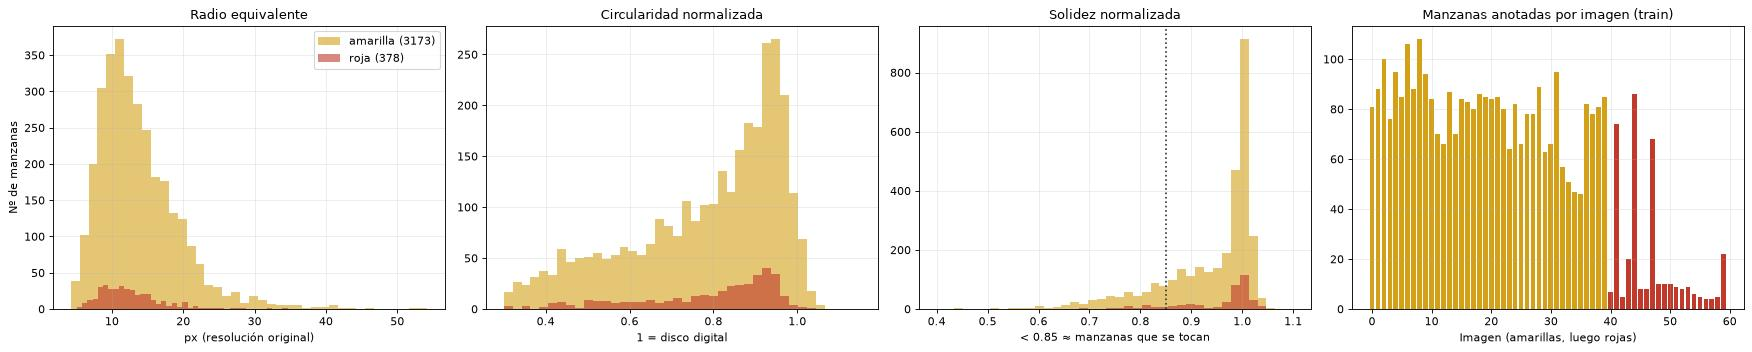

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for variety in ("amarilla", "roja"):
    o = [r for r in objects if r["variedad"] == variety]
    axes[0].hist([r["radio_equivalente"] for r in o], bins=40, alpha=0.6, color=COLORS[variety],
                 label=f"{variety} ({len(o)})")
    axes[1].hist([r["circularidad_norm"] for r in o], bins=40, range=(0.3, 1.15), alpha=0.6, color=COLORS[variety])
    axes[2].hist([r["solidez_norm"] for r in o], bins=40, range=(0.4, 1.1), alpha=0.6, color=COLORS[variety])
axes[0].set(title="Radio equivalente", xlabel="px (resolución original)", ylabel="Nº de manzanas")
axes[0].legend()
axes[1].set(title="Circularidad normalizada", xlabel="1 = disco digital")
axes[2].axvline(LOW_SOLIDITY, color="#333", linestyle=":")
axes[2].set(title="Solidez normalizada", xlabel=f"< {LOW_SOLIDITY} ≈ manzanas que se tocan")
ordered = sorted(per_image, key=lambda r: (r["variedad"], r["image_id"]))
axes[3].bar(range(len(ordered)), [r["manzanas"] for r in ordered], color=[COLORS[r["variedad"]] for r in ordered])
axes[3].set(title="Manzanas anotadas por imagen (train)", xlabel="Imagen (amarillas, luego rojas)")
fig.tight_layout()
save_fig(fig, "objetos_estadisticas.png")

**Interpretación y decisiones.**

- Las manzanas son **pequeñas** (radio típico ≈ 12 px a resolución original, ≈ 6 px a escala 0,5) y la mayoría son casi
  tan redondas como un disco (circularidad y solidez normalizadas medianas ≈ 0,83 y ≈ 0,98) → tiene sentido un **filtro
  por circularidad** y probar la **transformada de Hough de círculos**.
- Alrededor de un **17 %** de las componentes (más de un **25 %** del área) tienen solidez baja: manzanas que se tocan u
  ocluidas por hojas → **watershed** con transformada de distancia para separarlas y contarlas.
- Los valores orientativos impresos arriba (área mínima, radios de Hough, tamaño máximo de la apertura) serán el punto de
  partida de los rangos de Optuna. Una apertura mayor que 3×3 a escala 0,5 borraría las manzanas pequeñas.
- Hay un **desbalanceo entre variedades** a nivel de objeto: en train hay unas 3200 manzanas amarillas frente a menos de
  400 rojas. Los modelos supervisados deben muestrear por variedad o las rojas quedarán infrarrepresentadas.

## 8. Iluminación, sobreexposición y ruido

Los filtros y ajustes de contraste (temas 3 y 6) solo se justifican si el problema existe. Por imagen de train medimos:

- **Brillo L\*** (Lab) de manzanas y fondo, y su dispersión → variaciones sol/sombra → **CLAHE**.
- **Manzana en sombra**: fracción de píxeles de manzana con L\* < 100 (sobre 255).
- **Brillo especular**: V ≥ 245 y S < 60 (zonas casi blancas) → huecos en la máscara → **mediana** y **cierre**.
- **Sobreexposición**: algún canal RGB ≥ 250 (el sensor recorta).
- **Ruido gaussiano**: σ estimado con el método de **Immerkær (1996)**, una convolución con una máscara laplaciana de
  suma cero (tema 3), a resolución original.
- **Ruido impulsivo** (sal y pimienta): píxeles casi negros/blancos que difieren > 80 niveles de su mediana 3×3.

In [15]:
quality = []
for s in train:
    image, mask = resize(s)
    L = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)[:, :, 0].astype(float)
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    specular = (hsv[:, :, 2] >= 245) & (hsv[:, :, 1] < 60)
    saturated = image.max(axis=2) >= 250
    gray_full = cv2.cvtColor(s.image, cv2.COLOR_RGB2GRAY)
    quality.append({
        "image_id": s.image_id, "variedad": s.variety,
        "L_manzana": L[mask].mean(), "L_std_manzana": L[mask].std(), "L_fondo": L[~mask].mean(),
        "sombra": np.mean(L[mask] < 100), "especular": specular[mask].mean(),
        "sobreexpuesta": saturated[mask].mean(), "sobreexpuesto_fondo": saturated[~mask].mean(),
        "sigma_ruido": estimate_gaussian_noise(gray_full), "impulsivo": impulse_noise_fraction(gray_full),
    })
save_csv(quality, "iluminacion_por_imagen.csv")

rows = []
for g in GROUPS:
    q = [r for r in quality if g == "todas" or r["variedad"] == g]
    col = lambda k: np.array([r[k] for r in q])
    rows.append({
        "variedad": g,
        "L": f"{col('L_manzana').min():.0f} – {col('L_manzana').max():.0f}",
        "Lstd": fmt(np.median(col("L_std_manzana")), 1),
        "sombra": f"{pct(np.median(col('sombra')))} / {pct(col('sombra').max())}",
        "esp": f"{pct(np.median(col('especular')))} / {pct(col('especular').max())}",
        "sat": f"{pct(np.median(col('sobreexpuesta')))} (fondo {pct(np.median(col('sobreexpuesto_fondo')))})",
        "sigma": f"{fmt(col('sigma_ruido').min(), 2)} – {fmt(col('sigma_ruido').max(), 2)}",
        "imp": pct(col("impulsivo").max(), 3),
    })
table(rows, ["variedad", "L", "Lstd", "sombra", "esp", "sat", "sigma", "imp"],
      ["Variedad", "L* manzana (rango entre imágenes)", "Desv. L* dentro de imagen", "Manzana en sombra (mediana / máx)",
       "Brillo especular (mediana / máx)", "Manzana sobreexpuesta (mediana)", "σ ruido gaussiano", "Ruido impulsivo (máx)"])

| Variedad | L* manzana (rango entre imágenes) | Desv. L* dentro de imagen | Manzana en sombra (mediana / máx) | Brillo especular (mediana / máx) | Manzana sobreexpuesta (mediana) | σ ruido gaussiano | Ruido impulsivo (máx) |
|---|---|---|---|---|---|---|---|
| todas | 133 – 195 | 58,6 | 13,6 % / 19,7 % | 0,5 % / 10,3 % | 22,1 % (fondo 1,9 %) | 3,11 – 6,24 | 0,004 % |
| amarilla | 167 – 195 | 60,6 | 13,4 % / 19,4 % | 1,1 % / 10,3 % | 23,3 % (fondo 0,4 %) | 3,11 – 5,59 | 0,004 % |
| roja | 133 – 165 | 37,6 | 13,8 % / 19,7 % | 0,0 % / 0,1 % | 11,1 % (fondo 7,4 %) | 3,80 – 6,24 | 0,001 % |

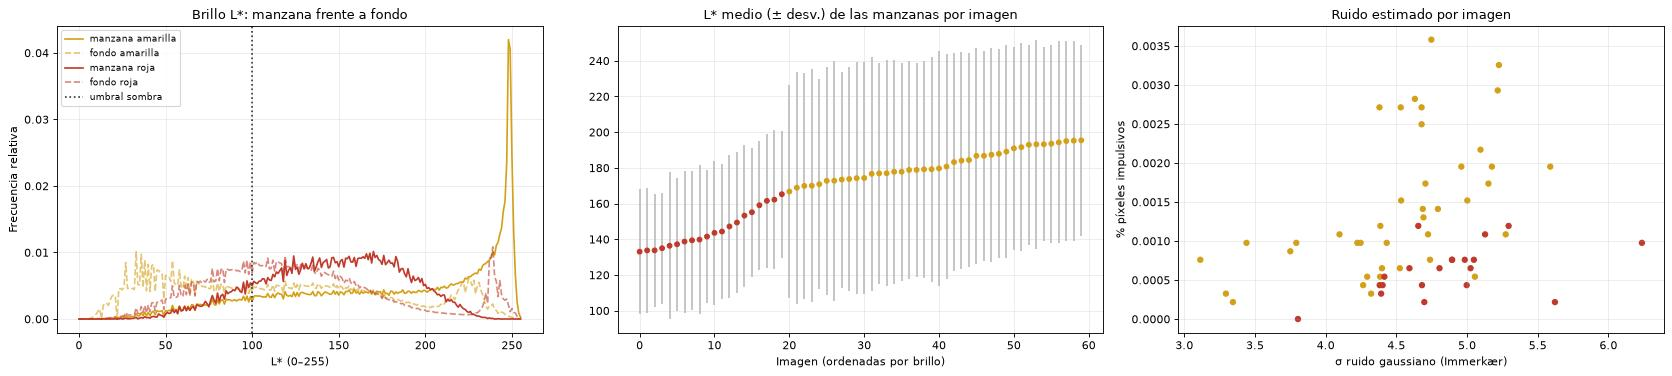

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(21, 4.8))
for variety in ("amarilla", "roja"):
    apple, background = np.zeros(256), np.zeros(256)
    for s in (s for s in train if s.variety == variety):
        image, mask = resize(s)
        L = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)[:, :, 0]
        apple += np.bincount(L[mask], minlength=256)
        background += np.bincount(L[~mask], minlength=256)
    axes[0].plot(apple / apple.sum(), color=COLORS[variety], label=f"manzana {variety}")
    axes[0].plot(background / background.sum(), "--", color=COLORS[variety], alpha=0.6, label=f"fondo {variety}")
axes[0].axvline(100, color="#333", linestyle=":", label="umbral sombra")
axes[0].set(title="Brillo L*: manzana frente a fondo", xlabel="L* (0–255)", ylabel="Frecuencia relativa")
axes[0].legend(fontsize=8)
q = sorted(quality, key=lambda r: r["L_manzana"])
axes[1].errorbar(range(len(q)), [r["L_manzana"] for r in q], yerr=[r["L_std_manzana"] for r in q],
                 fmt="none", ecolor="#bbb")
axes[1].scatter(range(len(q)), [r["L_manzana"] for r in q], c=[COLORS[r["variedad"]] for r in q], s=18, zorder=3)
axes[1].set(title="L* medio (± desv.) de las manzanas por imagen", xlabel="Imagen (ordenadas por brillo)")
axes[2].scatter([r["sigma_ruido"] for r in quality], [100 * r["impulsivo"] for r in quality],
                c=[COLORS[r["variedad"]] for r in quality], s=22)
axes[2].set(title="Ruido estimado por imagen", xlabel="σ ruido gaussiano (Immerkær)", ylabel="% píxeles impulsivos")
fig.tight_layout()
save_fig(fig, "iluminacion_calidad.png")

El histograma de L\* de las manzanas amarillas tiene un pico junto a 255. ¿Significa que el color se pierde (píxeles
blancos)? Lo comprobamos mirando el color de los píxeles sobreexpuestos:

In [17]:
pixels = np.concatenate([s.image[s.mask] for s in train if s.variety == "amarilla"])
sat = pixels.max(axis=1) >= 250
print(f"Píxeles de manzana amarilla sobreexpuestos: {pct(sat.mean())}  ·  blancos de verdad (R,G,B ≥ 250): "
      f"{pct((pixels.min(axis=1) >= 250).mean(), 2)}")
print("RGB medio de los sobreexpuestos:", pixels[sat].mean(axis=0).round(0),
      " · canal recortado → R:", pct((pixels[sat, 0] >= 250).mean(), 0), " G:", pct((pixels[sat, 1] >= 250).mean(), 0),
      " B:", pct((pixels[sat, 2] >= 250).mean(), 0))

Píxeles de manzana amarilla sobreexpuestos: 25,5 %  ·  blancos de verdad (R,G,B ≥ 250): 0,07 %
RGB medio de los sobreexpuestos: [253. 252. 109.]  · canal recortado → R: 91 %  G: 78 %  B: 1 %


**Interpretación y decisiones.**

- **Iluminación muy variable**: el L\* medio de las manzanas cambia mucho entre imágenes y, dentro de cada una, la
  desviación es grande (sol frente a sombra; un 13–20 % de los píxeles de manzana están en sombra). Justifica
  **CLAHE** sobre L\* (o V), que ecualiza el contraste por regiones sin tocar el color.
- **Sobreexposición en las amarillas**: alrededor de una cuarta parte de sus píxeles de manzana tienen R y G recortados
  a 255, pero B sigue bajo (≈ 110): siguen siendo **amarillo intenso, no blanco**. El brillo deja de ser fiable ahí (ni
  gamma ni CLAHE recuperan lo recortado), pero **los canales cromáticos siguen funcionando**: otra razón para segmentar
  por color y no por brillo.
- **Brillos especulares**: poco frecuentes en general, pero en algunas imágenes amarillas llegan al ~10 % de la manzana
  → huecos blancos dentro de las manzanas → **mediana** y **cierre morfológico**.
- **Ruido bajo**: σ gaussiano de 3 a 6 niveles de gris y prácticamente **ningún píxel de sal y pimienta** natural. El
  suavizado (gaussiano, bilateral) servirá más para homogeneizar la textura de las hojas que para quitar ruido de sensor,
  y el filtro de mediana frente a impulsos se evaluará con **ruido sintético** (experimento de robustez del preprocesado,
  con `src/preprocesado/ruido.py`).

## 9. ¿Son completas las anotaciones?

El enunciado pide identificar las manzanas del **árbol situado frente al robot**. En las imágenes se ven también frutos
de las filas del fondo. Comprobamos si están anotados: umbralizamos el mejor gris de manzana con su umbral de máximo F1
y miramos las regiones del tamaño de una manzana que caen **fuera** de la máscara. Se muestra la imagen roja de
validación con más píxeles detectados fuera de la máscara (el peor caso, a propósito).

img_083: 35 regiones del tamaño de una manzana detectadas por color que no tocan ninguna anotación (umbral 159 sobre '(Cr + 255 − Cb) / 2').


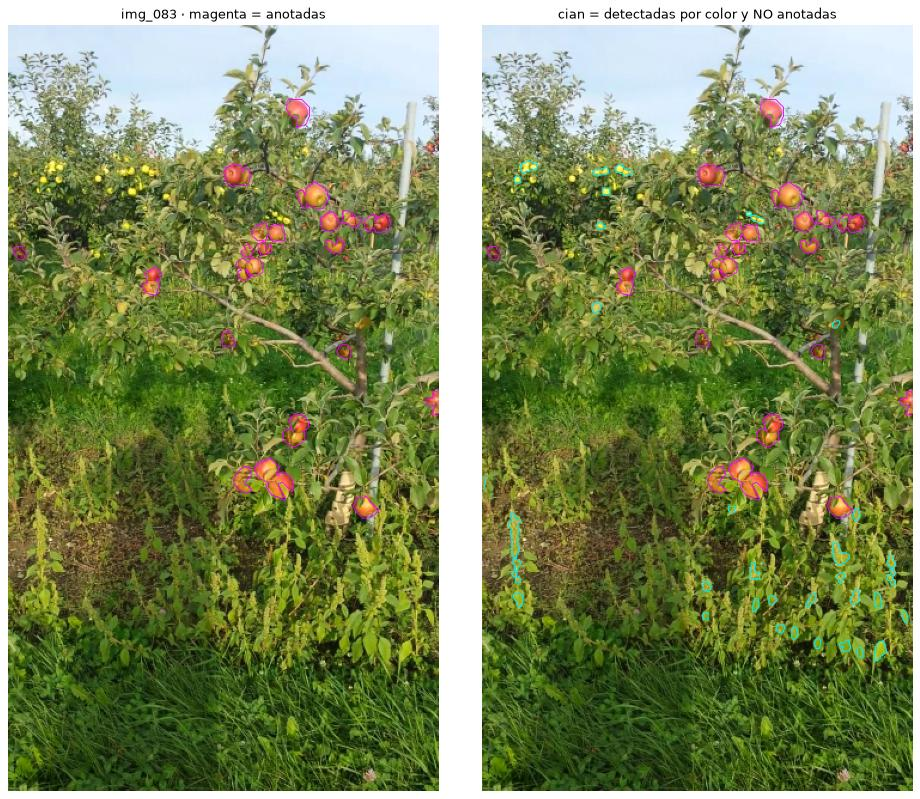

In [18]:
best_name = order[0]
threshold = get(best_name, "todas", "umbral_mejor_f1")
function = candidates[best_name]
s = max((s for s in validation if s.variety == "roja"),
        key=lambda s: int((function(resize(s)[0]) >= threshold)[~resize(s)[1]].sum()))
image, mask = resize(s)
detected = (function(image) >= threshold).astype(np.uint8)
detected = cv2.morphologyEx(detected, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
count, labels, stats, _ = cv2.connectedComponentsWithStats(detected, connectivity=8)
unannotated = np.zeros_like(mask)
for label in range(1, count):
    region = labels == label
    if stats[label, cv2.CC_STAT_AREA] >= min_area and not (region & mask).any():
        unannotated |= region
print(f"{s.image_id}: {cv2.connectedComponents(unannotated.astype(np.uint8))[0] - 1} regiones del tamaño de una "
      f"manzana detectadas por color que no tocan ninguna anotación (umbral {threshold} sobre '{best_name}').")

fig, axes = plt.subplots(1, 2, figsize=(12, 10))
axes[0].imshow(image)
axes[0].contour(mask, levels=[0.5], colors="#ff00ff", linewidths=0.8)
axes[0].set_title(f"{s.image_id} · magenta = anotadas")
axes[1].imshow(image)
axes[1].contour(mask, levels=[0.5], colors="#ff00ff", linewidths=0.8)
axes[1].contour(unannotated, levels=[0.5], colors="#00e5ff", linewidths=1.0)
axes[1].set_title("cian = detectadas por color y NO anotadas")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
save_fig(fig, "anotaciones_incompletas.png")

**Interpretación.** En la parte superior izquierda se ven decenas de **manzanas amarillas de la fila del fondo sin
anotar**; unas cuantas superan el umbral y el área mínima (contornos cian de arriba). La mayoría de las regiones cian, en
cambio, son **hierbas y tallos iluminados** de la parte baja. Consecuencias:

- Las anotaciones **solo cubren el árbol de delante**. Lo que un método de color detecte en los árboles del fondo contará
  como **falso positivo** aunque sea una manzana: la precisión medida será algo más baja que la real, sobre todo en las
  imágenes rojas, y explica en parte el AP tan bajo de los canales amarillos en ellas (sección 6).
- El **filtro de área mínima** descarta la mayoría de esas manzanas lejanas (se ven más pequeñas), y debe explicarse en
  la discusión de la memoria como una limitación de las anotaciones, no del modelo.
- Las hierbas iluminadas tienen el mismo color que una manzana pero **forma alargada e irregular**: confirma que hace falta
  el filtro por **circularidad/solidez** o información de textura y vecindad en los modelos.

## 10. Conclusiones: qué decide este EDA

| Hallazgo (sección) | Decisión | Fase |
|---|---|---|
| 66 imágenes amarillas (`img_000`–`065`) y 34 rojas (`066`–`099`) (2) | Split estratificado 60/20/20 y análisis por variedad | Datos |
| ~4 % de píxeles de manzana; todo fondo da accuracy 0,96 con F1 = 0 (4) | Métricas F1/Dice, IoU, MCC, PR-AUC; muestreo balanceado | Métricas, modelos |
| El gris estándar separa mal (AUC 0,65 en rojas) (5) | P0 (sin preprocesado) será la línea base mala, como predice el profesor | Experimentos |
| Cada variedad tiene su canal: Cb/b\* (amarillas), Cr/a\*/matiz (rojas) (5) | Convertir a YCrCb/Lab; matiz como distancia circular al rojo | Preprocesado (P5) |
| (Cr + 255 − Cb)/2 multiplica por ~5 el AP del gris estándar (6) | "Gris de manzana" principal; retroproyección como alternativa aprendida | Preprocesado (P6) |
| Manzanas pequeñas (r ≈ 6 px a escala 0,5) y casi redondas (7) | Área mínima, apertura ≤ 3×3, filtro de circularidad, Hough con radios 3–17 px | Postprocesado, M8 |
| ~17 % de manzanas fusionadas u ocluidas (7) | Watershed para separar y contar | Postprocesado, métricas por objeto |
| Muchas más manzanas amarillas que rojas (7) | Muestreo por variedad en modelos supervisados | Modelos |
| Iluminación sol/sombra muy variable (8) | CLAHE sobre L\* | Preprocesado (P4) |
| Sobreexposición en amarillas, pero el color se conserva (8) | Segmentar por color, no por brillo | Preprocesado |
| Brillos especulares puntuales (8) | Mediana + cierre morfológico | Preprocesado, postprocesado |
| Ruido bajo y sin sal y pimienta natural (8) | Evaluar filtros de ruido con ruido sintético | Experimento de robustez |
| Manzanas del fondo no anotadas; hierbas iluminadas con color de manzana (9) | Filtro de área y de forma; explicarlo en la discusión | Postprocesado, memoria |

Todos los CSV y figuras se guardan en `resultados/eda/` para usarlos en la memoria (LaTeX).

**Reproducir:** `jupyter nbconvert --to notebook --execute --inplace experimentos/eda.ipynb` (≈ 20 s) o abrirlo con
`jupyter lab` y ejecutar todas las celdas.